# 1. Data and features

MASC 520 final project was done by Yunshuo Tian & Shaojinlin Yang

what we did in this notebook
1. download semiconductors' band gap & crystal structure from the Materials Project,
2. compute 17 features for each chemicals
3. save it to `data/features.csv` for next notebook.

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymatgen.core import Structure, Element

warnings.filterwarnings("ignore")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## 1.1 Download from the Materials Project

which material we selected:
- The band gap between 0.1 and 3.0 eV (only semiconductors)
- simple compounds(2~3 element), up to 10 atoms 
- energy above hull ≤ 0.05 eV/atom 
- Excluded nobel gas and f-block element

You need a free API key, the link is from here - https://next-gen.materialsproject.org/api.

In [ ]:
API_KEY = "paste your Materials Project API key here"

f_block = "La Ce Pr Nd Pm Sm Eu Gd Tb Dy Ho Er Tm Yb Lu Ac Th Pa U Np Pu Am Cm Bk Cf Es Fm Md No Lr".split()
noble_gas = "He Ne Ar Kr Xe Rn".split()
excluded = set(f_block + noble_gas)

if os.path.exists("data/materials.csv"):
    print("data/materials.csv found, Don't need to download anymore")
else:
    from mp_api.client import MPRester
    with MPRester(API_KEY) as mpr:
        docs = mpr.materials.summary.search(
            band_gap=(0.1, 3.0),
            energy_above_hull=(0, 0.05),
            num_elements=(2, 3),
            num_sites=(1, 10),
            fields=["material_id", "band_gap", "energy_above_hull", "symmetry", "structure"],
        )
    rows = []
    for d in docs:
        s = d.structure
        elements = [e.symbol for e in s.composition]
        if s.is_ordered and not excluded.intersection(elements):
            rows.append({
                "material_id": str(d.material_id),
                "formula": s.composition.reduced_formula,
                "band_gap": d.band_gap,
                "e_above_hull": d.energy_above_hull,
                "crystal_system": str(d.symmetry.crystal_system.value).lower(),
                "cif": s.to(fmt="cif"),
            })
    pd.DataFrame(rows).to_csv("data/materials.csv", index=False)

Retrieving SummaryDoc documents: 100%|██████████| 2833/2833 [00:03<00:00, 745.89it/s] 


In [5]:
data = pd.read_csv("data/materials.csv")
print("materials:", len(data))
print("distinct formulas:", data.formula.nunique())
data[["material_id", "formula", "band_gap", "crystal_system"]].head()

materials: 2309
distinct formulas: 1842


,material_id,formula,band_gap,crystal_system
0,mp-23485,Ag2HgI4,1.2219,tetragonal
1,mp-570256,Ag2HgI4,1.1004,tetragonal
2,mp-1229122,Ag2HgI4,1.2764,tetragonal
3,mp-9635,Ag2HgS2,0.4191,monoclinic
4,mp-546190,Ag2O3,0.3425,orthorhombic


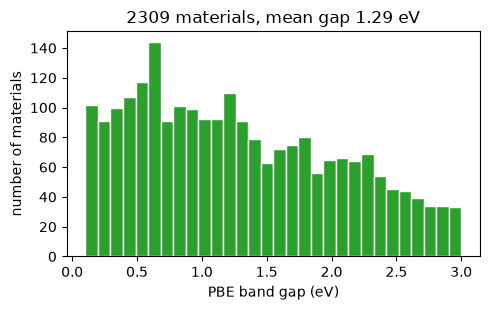

In [6]:
plt.figure(figsize=(5, 3.2))
plt.hist(data.band_gap, bins=30, color="tab:green", edgecolor="white")
plt.xlabel("PBE band gap (eV)")
plt.ylabel("number of materials")
plt.title(f"{len(data)} materials, mean gap {data.band_gap.mean():.2f} eV")
plt.tight_layout()
plt.savefig("figures/fig1_gap_distribution.png", dpi=200)
plt.show()

## 1.2 Features

The idea is from cluster expansion. A property can be described by point term (one atom) and pair term (two atoms) with triplets. 
we only keep point term and pair term.


- Composition (point terms), 13 features: for each element property we only calculate the
fraction-weighted mean and the difference between maximum and minimum, over the elements in the compound

| feature | meaning |

| `X_mean`, `X_diff` | electronegativity —— how ionic the bonds are |
| `radius_mean`, `radius_diff` | atomic radius |
| `IE_mean`, `IE_diff` | first ionization energy |
| `row_mean`, `row_diff` | period in the periodic table |
| `group_mean`, `group_diff` | group in the periodic table |
| `s_val`, `p_val`, `d_val` | average  s, p, d valence electrons |

- Nearest neighbours (pair terms), 4 features: for every atom we look at its first
neighbour shell and take the average over all atoms

| feature | meaning |

| `nn_dist` | bond length, Å |
| `coord` | coordination number |
| `bond_ratio` | bond length between atom 1 and atom 2 |
| `unlike_frac` | fraction of nearest neighbours |

We also investigate cell volume per atom, density, packing fraction and crystal system,
but they wouldn't increase the accuracy, so they excluded from the data set.

In [7]:
def valence_electrons(el):
    # s and p electrons in the outer shell, d electrons one shell below
    shells = {(n, l): count for n, l, count in el.full_electronic_structure}
    s = shells.get((el.row, "s"), 0)
    p = shells.get((el.row, "p"), 0)
    d = shells.get((el.row - 1, "d"), 0)
    return s, p, d


def composition_features(structure):
    comp = structure.composition.fractional_composition
    elements = [Element(e.symbol) for e in comp]
    frac = np.array([comp[e] for e in elements])

    feats = {}
    properties = {
        "X": [e.X for e in elements],
        "radius": [e.atomic_radius for e in elements],
        "IE": [e.ionization_energy for e in elements],
        "row": [e.row for e in elements],
        "group": [e.group for e in elements],
    }
    for name, values in properties.items():
        values = np.array(values, dtype=float)
        feats[name + "_mean"] = np.sum(frac * values)
        feats[name + "_diff"] = values.max() - values.min()

    val = np.array([valence_electrons(e) for e in elements], dtype=float)
    feats["s_val"], feats["p_val"], feats["d_val"] = np.sum(frac[:, None] * val, axis=0)
    return feats


def neighbour_features(structure, cutoff=4.0):
    nn_dist, coord, bond_ratio, unlike = [], [], [], []
    for i, neighbours in enumerate(structure.get_all_neighbors(cutoff)):
        if len(neighbours) == 0:
            continue
        nearest = min(neighbours, key=lambda n: n.nn_distance)
        d_min = nearest.nn_distance
        # first shell = neighbours within 0.3 Å of the closest one
        shell = [n for n in neighbours if n.nn_distance < d_min + 0.3]
        atom = structure[i].specie
        nn_dist.append(d_min)
        coord.append(len(shell))
        bond_ratio.append(d_min / (atom.atomic_radius + nearest.specie.atomic_radius))
        unlike.append(np.mean([n.specie != atom for n in shell]))
    if len(nn_dist) == 0:          # no atom within the cutoff
        return {"nn_dist": np.nan, "coord": np.nan, "bond_ratio": np.nan, "unlike_frac": np.nan}
    return {"nn_dist": np.mean(nn_dist), "coord": np.mean(coord),
            "bond_ratio": np.mean(bond_ratio), "unlike_frac": np.mean(unlike)}

In [8]:
# quick check on GaAs (zinc blende): every atom has 4 neighbours of the other element
gaas = data[data.formula == "GaAs"].iloc[0]
s = Structure.from_str(gaas.cif, fmt="cif")
print(gaas.material_id, gaas.band_gap, "eV")
print(composition_features(s))
print(neighbour_features(s))

mp-2534 0.1839000000000004 eV
{'X_mean': np.float64(1.995), 'X_diff': np.float64(0.3700000000000001), 'radius_mean': np.float64(1.225), 'radius_diff': np.float64(0.15000000000000013), 'IE_mean': np.float64(7.893926), 'IE_diff': np.float64(3.7892480000000006), 'row_mean': np.float64(4.0), 'row_diff': np.float64(0.0), 'group_mean': np.float64(14.0), 'group_diff': np.float64(2.0), 's_val': np.float64(2.0), 'p_val': np.float64(2.0), 'd_val': np.float64(10.0)}
{'nn_dist': np.float64(2.4899017527871283), 'coord': np.float64(4.0), 'bond_ratio': np.float64(1.016286429709032), 'unlike_frac': np.float64(1.0)}


In [9]:
rows = []
for i, row in data.iterrows():
    s = Structure.from_str(row.cif, fmt="cif")
    f = {"material_id": row.material_id, "formula": row.formula, "band_gap": row.band_gap}
    f.update(composition_features(s))
    f.update(neighbour_features(s))
    rows.append(f)
    if i % 500 == 0:
        print(i, "/", len(data))

features = pd.DataFrame(rows)
print("rows with missing values:", features.isna().any(axis=1).sum())
features = features.dropna().reset_index(drop=True)
features.to_csv("data/features.csv", index=False)
print("saved", features.shape)

0 / 2309
500 / 2309
1000 / 2309
1500 / 2309
2000 / 2309
rows with missing values: 2
saved (2307, 20)


In [10]:
features.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
band_gap,2307.0,1.29,0.77,0.10,0.63,1.18,1.89,3.00
X_mean,2307.0,2.28,0.50,1.11,1.93,2.26,2.58,3.74
X_diff,2307.0,1.54,0.78,0.01,0.93,1.54,2.14,3.19
radius_mean,2307.0,1.25,0.28,0.50,1.07,1.25,1.44,2.22
radius_diff,2307.0,0.87,0.50,0.00,0.45,0.85,1.20,2.35
IE_mean,2307.0,9.67,2.01,4.88,8.25,9.44,10.69,16.02
IE_diff,2307.0,5.87,3.04,0.01,3.39,5.58,8.23,13.53
row_mean,2307.0,3.73,0.84,1.50,3.00,3.71,4.33,6.00
row_diff,2307.0,2.22,1.15,0.00,1.00,2.00,3.00,5.00
group_mean,2307.0,11.74,3.02,1.00,9.75,12.50,14.00,17.00


## 1.3 First look: how does each feature relate to the band gap?

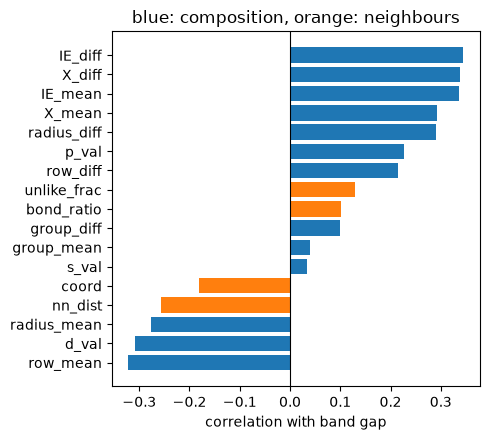

In [11]:
COMP = ["X_mean", "X_diff", "radius_mean", "radius_diff", "IE_mean", "IE_diff",
        "row_mean", "row_diff", "group_mean", "group_diff", "s_val", "p_val", "d_val"]
PAIR = ["nn_dist", "coord", "bond_ratio", "unlike_frac"]

corr = features[COMP + PAIR].corrwith(features.band_gap).sort_values()
colors = ["tab:orange" if c in PAIR else "tab:blue" for c in corr.index]

plt.figure(figsize=(5, 4.5))
plt.barh(corr.index, corr.values, color=colors)
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("correlation with band gap")
plt.title("blue: composition, orange: neighbours")
plt.tight_layout()
plt.savefig("figures/fig2_feature_correlation.png", dpi=200)
plt.show()

##summary
- larger electronegativity difference, has a larger gap;
- heavier elements (larger row) & bigger atoms, longer bonds and more d electrons, then has a  smaller gap.
- No single feature has a correlation above 0.35, so a nonlinear model is needed.